In [25]:
from pathlib import Path


dataset_dir = Path('Dataset').resolve()
print(dataset_dir)

C:\mit\Mini Project\Project\Dataset


In [26]:
import sys
print(sys.executable)

c:\Users\vaibhavi nayak\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
# Loading the dataset from the local Dataset folder
base_dir = Path.cwd()
dataset_dir = base_dir / 'Dataset'

data1 = pd.read_csv(dataset_dir / 'Monday-WorkingHours.pcap_ISCX.csv')
data2 = pd.read_csv(dataset_dir / 'Tuesday-WorkingHours.pcap_ISCX.csv')
data3 = pd.read_csv(dataset_dir / 'Wednesday-workingHours.pcap_ISCX.csv')
data4 = pd.read_csv(dataset_dir / 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv')
data5 = pd.read_csv(dataset_dir / 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv')

data6 = pd.read_csv(dataset_dir / 'Friday-WorkingHours-Morning.pcap_ISCX.csv')
data8 = pd.read_csv(dataset_dir / 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')
data7 = pd.read_csv(dataset_dir / 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv')

In [29]:
data_list = [data1, data2, data3, data4, data5, data6, data7, data8]

print('Data dimensions: ')
for i, data in enumerate(data_list, start = 1):
  rows, cols = data.shape
  print(f'Data{i} -> {rows} rows, {cols} columns')

Data dimensions: 
Data1 -> 529918 rows, 79 columns
Data2 -> 445909 rows, 79 columns
Data3 -> 692703 rows, 79 columns
Data4 -> 170366 rows, 79 columns
Data5 -> 288602 rows, 79 columns
Data6 -> 191033 rows, 79 columns
Data7 -> 286467 rows, 79 columns
Data8 -> 225745 rows, 79 columns


In [30]:
data = pd.concat(data_list)
rows, cols = data.shape

print('New dimension:')
print(f'Number of rows: {rows}')
print(f'Number of columns: {cols}')
print(f'Total cells: {rows * cols}')

New dimension:
Number of rows: 2830743
Number of columns: 79
Total cells: 223628697


In [31]:

# Deleting dataframes after concating to save memory
for d in data_list: del d

In [32]:
# Renaming the columns by removing leading/trailing whitespace
col_names = {col: col.strip() for col in data.columns}
data.rename(columns = col_names, inplace = True)

In [33]:
data.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

In [34]:
# Creating a dictionary that maps each label to its attack type
attack_map = {
    'BENIGN': 'BENIGN',
    'DDoS': 'DDoS',
    'DoS Hulk': 'DoS',
    'DoS GoldenEye': 'DoS',
    'DoS slowloris': 'DoS',
    'DoS Slowhttptest': 'DoS',
    'PortScan': 'Port Scan',
    'FTP-Patator': 'Brute Force',
    'SSH-Patator': 'Brute Force',
    'Bot': 'Bot',
    'Web Attack � Brute Force': 'Web Attack',
    'Web Attack � XSS': 'Web Attack',
    'Web Attack � Sql Injection': 'Web Attack',
    'Infiltration': 'Infiltration',
    'Heartbleed': 'Heartbleed'
}

# Creating a new column 'Attack Type' in the DataFrame based on the attack_map dictionary
data['Attack Type'] = data['Label'].map(attack_map)

In [35]:
data['Attack Type'].value_counts()

Attack Type
BENIGN          2273097
DoS              252661
Port Scan        158930
DDoS             128027
Brute Force       13835
Web Attack         2180
Bot                1966
Infiltration         36
Heartbleed           11
Name: count, dtype: int64

In [36]:
data.drop('Label', axis = 1, inplace = True)

In [37]:
# Separate original features and target
X = data.drop('Attack Type', axis=1)
y = data['Attack Type']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
print(y.value_counts())

Feature shape: (2830743, 78)
Target shape: (2830743,)

Target class distribution:
Attack Type
BENIGN          2273097
DoS              252661
Port Scan        158930
DDoS             128027
Brute Force       13835
Web Attack         2180
Bot                1966
Infiltration         36
Heartbleed           11
Name: count, dtype: int64


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (2123057, 78)
Testing shape: (707686, 78)


In [39]:
import numpy as np

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Missing values in training data:", X_train.isna().sum().sum())
print("Missing values in testing data:", X_test.isna().sum().sum())

Missing values in training data: 4278
Missing values in testing data: 1456


In [40]:
from sklearn.impute import SimpleImputer
import numpy as np

# Replace infinite values with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

# Create the imputer
imputer = SimpleImputer(strategy='median')

# Fit only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply the same imputer to test data
X_test_imputed = imputer.transform(X_test)

print("Missing values after imputation:",
      np.isnan(X_train_imputed).sum(),
      np.isnan(X_test_imputed).sum())

print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

Missing values after imputation: 0 0
Training shape: (2123057, 78)
Testing shape: (707686, 78)


In [41]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# Reconstruct the imputed training data
X_train_imp_df = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

# Attach the training labels
rf_data = X_train_imp_df.copy()
rf_data['Attack Type'] = y_train

# Select at most 5,000 records per class
rf_sample = (
    rf_data.groupby('Attack Type', group_keys=False)
    .sample(frac=1, random_state=0)
    .groupby('Attack Type', group_keys=False)
    .head(5000)
)

# Separate features and target
X_rf = rf_sample.drop(columns=['Attack Type'])
y_rf = rf_sample['Attack Type']

print("Sample shape:", X_rf.shape)
print("Target classes:", y_rf.nunique())
print(y_rf.value_counts())

Sample shape: (28145, 78)
Target classes: 9
Attack Type
BENIGN          5000
Brute Force     5000
DDoS            5000
DoS             5000
Port Scan       5000
Web Attack      1635
Bot             1475
Infiltration      27
Heartbleed         8
Name: count, dtype: int64


In [42]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced_subsample',
    min_samples_leaf=2,
    random_state=0,
    n_jobs=-1
)

rf.fit(X_rf, y_rf)

rf_importance = pd.DataFrame({
    'Feature': X_rf.columns,
    'Importance': rf.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

print(rf_importance.head(30).to_string(index=False))

                    Feature  Importance
           Destination Port    0.090831
    Init_Win_bytes_backward    0.055096
      Fwd Packet Length Max    0.032050
     Bwd Packet Length Mean    0.031639
Total Length of Bwd Packets    0.028827
          Subflow Bwd Bytes    0.028601
         Packet Length Mean    0.027752
      Bwd Packet Length Max    0.027747
Total Length of Fwd Packets    0.027378
       Avg Bwd Segment Size    0.027285
     Init_Win_bytes_forward    0.027135
          Subflow Fwd Bytes    0.026979
          Max Packet Length    0.025155
     Fwd Packet Length Mean    0.024484
        Average Packet Size    0.024361
       Avg Fwd Segment Size    0.022316
          Bwd Header Length    0.021460
       min_seg_size_forward    0.020323
              Bwd Packets/s    0.020301
        Fwd Header Length.1    0.019644
          Fwd Header Length    0.018938
               Flow Bytes/s    0.016877
      Bwd Packet Length Std    0.016787
          Packet Length Std    0.016518


In [43]:
top_20_features = rf_importance.head(20)['Feature'].tolist()
top_30_features = rf_importance.head(30)['Feature'].tolist()

In [44]:
from sklearn.model_selection import train_test_split

X_dev, X_val, y_dev, y_val = train_test_split(
    X_train_imp_df,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Development set:", X_dev.shape)
print("Validation set:", X_val.shape)
print("Development classes:", y_dev.nunique())
print("Validation classes:", y_val.nunique())

Development set: (1698445, 78)
Validation set: (424612, 78)
Development classes: 9
Validation classes: 9


In [45]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# Combine development features and labels
rf_data = X_dev.copy()
rf_data['Attack Type'] = y_dev

# Select up to 5,000 records from each class
rf_sample = pd.concat([
    group.sample(
        n=min(len(group), 5000),
        random_state=0
    )
    for _, group in rf_data.groupby('Attack Type')
], ignore_index=True)

# Separate features and target
X_rf = rf_sample.drop(columns=['Attack Type'])
y_rf = rf_sample['Attack Type']

print("Sample shape:", X_rf.shape)
print("\nClass distribution:")
print(y_rf.value_counts())

Sample shape: (27516, 78)

Class distribution:
Attack Type
BENIGN          5000
Brute Force     5000
DDoS            5000
DoS             5000
Port Scan       5000
Web Attack      1308
Bot             1180
Infiltration      22
Heartbleed         6
Name: count, dtype: int64


In [46]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced_subsample',
    min_samples_leaf=2,
    random_state=0,
    n_jobs=-1
)

rf.fit(X_rf, y_rf)

print("Random Forest training completed.")

Random Forest training completed.


In [47]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [48]:
import shap
print("SHAP version:", shap.__version__)

c:\Users\vaibhavi nayak\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1


In [49]:
# Select 100 records for the initial experiment
X_interaction = X_rf.sample(
    n=min(100, len(X_rf)),
    random_state=42
)

# Create an explainer for the trained Random Forest
explainer = shap.TreeExplainer(rf)

# Calculate feature interaction values
interaction_values = explainer.shap_interaction_values(
    X_interaction
)

print("Interaction analysis completed.")
print("Interaction output type:", type(interaction_values))

Interaction analysis completed.
Interaction output type: <class 'numpy.ndarray'>


In [50]:
# Convert the SHAP output into a NumPy array
if isinstance(interaction_values, list):
    # Older SHAP versions may return one array per class
    interaction_array = np.stack(interaction_values, axis=-1)
else:
    interaction_array = np.asarray(interaction_values)

print("Interaction array shape:", interaction_array.shape)

Interaction array shape: (100, 78, 78, 9)


In [51]:
# Average absolute interaction strength across records and classes
interaction_strength = np.mean(
    np.abs(interaction_array),
    axis=(0, 3)
)

# Remove individual-feature effects on the diagonal
np.fill_diagonal(interaction_strength, 0)

feature_names = list(X_rf.columns)

# Extract every unique pair once
pairs = []

for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        pairs.append({
            "Feature 1": feature_names[i],
            "Feature 2": feature_names[j],
            "Interaction Strength": interaction_strength[i, j]
        })

top_interactions = (
    pd.DataFrame(pairs)
    .sort_values("Interaction Strength", ascending=False)
    .reset_index(drop=True)
)

print(top_interactions.head(20).to_string(index=False))

              Feature 1                   Feature 2  Interaction Strength
       Destination Port        min_seg_size_forward              0.002335
       Destination Port       Bwd Packet Length Min              0.001655
       Destination Port     Init_Win_bytes_backward              0.001505
       Destination Port          Packet Length Mean              0.001125
       Destination Port         Average Packet Size              0.001100
       Destination Port           Subflow Fwd Bytes              0.000949
       Destination Port        Avg Fwd Segment Size              0.000937
Init_Win_bytes_backward        min_seg_size_forward              0.000910
       Destination Port Total Length of Fwd Packets              0.000864
       Destination Port       Fwd Packet Length Max              0.000848
  Bwd Packet Length Min        min_seg_size_forward              0.000821
 Init_Win_bytes_forward     Init_Win_bytes_backward              0.000817
       Destination Port           Subf

In [52]:
# Top 30 individual features
top_30_features = rf_importance.head(30)["Feature"].tolist()

# Collect the features appearing in the top 20 interaction pairs
interaction_features = set(
    top_interactions.head(20)["Feature 1"]
).union(
    set(top_interactions.head(20)["Feature 2"])
)

# Combine top individual features and interaction-related features
combined_features = list(dict.fromkeys(
    top_30_features + sorted(interaction_features)
))

print("All features:", len(X_dev.columns))
print("Top 30 features:", len(top_30_features))
print("Features in top interaction pairs:", len(interaction_features))
print("Combined feature set:", len(combined_features))

All features: 78
Top 30 features: 30
Features in top interaction pairs: 16
Combined feature set: 30


In [53]:
rf_importance = pd.DataFrame({
    'Feature': X_rf.columns,
    'Importance': rf.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print(rf_importance.head(30).to_string(index=False))

                    Feature  Importance
           Destination Port    0.101694
    Init_Win_bytes_backward    0.055001
          Subflow Bwd Bytes    0.034406
Total Length of Bwd Packets    0.030382
     Bwd Packet Length Mean    0.029280
      Fwd Packet Length Max    0.029233
          Subflow Fwd Bytes    0.028002
         Packet Length Mean    0.027768
Total Length of Fwd Packets    0.027403
        Average Packet Size    0.025963
       Avg Bwd Segment Size    0.025333
          Fwd Header Length    0.025213
       Avg Fwd Segment Size    0.024275
       min_seg_size_forward    0.024035
      Bwd Packet Length Max    0.023586
          Max Packet Length    0.022036
          Bwd Header Length    0.021835
      Bwd Packet Length Min    0.021707
        Fwd Header Length.1    0.021501
     Fwd Packet Length Mean    0.020218
     Init_Win_bytes_forward    0.019261
               Flow Bytes/s    0.018881
              Bwd Packets/s    0.016320
     Total Backward Packets    0.015906


In [54]:
# Feature set 1: All 78 features
all_features = list(X_rf.columns)

# Feature set 2: Top 30 Random Forest features
top_30_features = rf_importance.head(30)['Feature'].tolist()

# Feature set 3: Top 30 features plus features from SHAP
# interactions that are not already in the top 30
interaction_features = set(
    top_interactions.head(20)['Feature 1']
).union(
    set(top_interactions.head(20)['Feature 2'])
)

additional_features = sorted(
    interaction_features - set(top_30_features)
)

combined_features = top_30_features + additional_features

print("All features:", len(all_features))
print("Top 30 features:", len(top_30_features))
print("Additional SHAP interaction features:", len(additional_features))
print("Combined features:", len(combined_features))

print("\nAdditional features identified through SHAP:")
print(additional_features)

All features: 78
Top 30 features: 30
Additional SHAP interaction features: 0
Combined features: 30

Additional features identified through SHAP:
[]


In [55]:
print("All features:", len(all_features))
print("Top 30 features:", len(top_30_features))
print("Additional SHAP features:", len(additional_features))
print("Combined features:", len(combined_features))
print("Additional features:", additional_features)

All features: 78
Top 30 features: 30
Additional SHAP features: 0
Combined features: 30
Additional features: []


In [56]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import pandas as pd
import time

feature_sets = {
    "All 78 features": all_features,
    "Top 30 features": top_30_features
}

results = []
trained_models = {}

for name, selected_features in feature_sets.items():

    print(f"\nTraining model: {name}")

    model = RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=0,
        n_jobs=-1
    )

    start_time = time.time()

    model.fit(
        X_rf[selected_features],
        y_rf
    )

    training_time = time.time() - start_time

    # Predict on the same validation set
    y_pred = model.predict(
        X_val[selected_features]
    )

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(
        y_val, y_pred,
        average="macro",
        zero_division=0
    )
    weighted_f1 = f1_score(
        y_val, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Feature Set": name,
        "Number of Features": len(selected_features),
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Training Time (seconds)": round(training_time, 2)
    })

    trained_models[name] = model

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Training time: {training_time:.2f} seconds")

comparison_df = pd.DataFrame(results)

print("\nFinal Comparison:")
print(comparison_df.to_string(index=False))



Training model: All 78 features
Accuracy: 0.9912
Macro F1: 0.7723
Weighted F1: 0.9935
Training time: 1.01 seconds

Training model: Top 30 features
Accuracy: 0.9924
Macro F1: 0.7584
Weighted F1: 0.9941
Training time: 0.82 seconds

Final Comparison:
    Feature Set  Number of Features  Accuracy  Macro F1  Weighted F1  Training Time (seconds)
All 78 features                  78  0.991230  0.772265     0.993464                     1.01
Top 30 features                  30  0.992412  0.758425     0.994084                     0.82


In [57]:

from sklearn.metrics import classification_report
import pandas as pd

for name, model in trained_models.items():
    selected_features = feature_sets[name]

    y_pred = model.predict(X_val[selected_features])

    report = classification_report(
        y_val,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    # Show the individual attack classes, excluding summary rows
    report_df = report_df.loc[
        ~report_df.index.isin(
            ["accuracy", "macro avg", "weighted avg"]
        )
    ]

    print(f"\n{name}")
    print(
        report_df[
            ["precision", "recall", "f1-score", "support"]
        ].round(4).to_string()
    )



All 78 features
              precision  recall  f1-score   support
BENIGN           0.9998  0.9894    0.9946  340965.0
Bot              0.1111  1.0000    0.1999     295.0
Brute Force      0.9389  0.9995    0.9683    2075.0
DDoS             0.9978  0.9992    0.9985   19204.0
DoS              0.9790  0.9986    0.9887   37899.0
Heartbleed       0.2222  1.0000    0.3636       2.0
Infiltration     1.0000  0.4000    0.5714       5.0
Port Scan        0.9918  0.9984    0.9951   23840.0
Web Attack       0.7797  0.9847    0.8703     327.0

Top 30 features
              precision  recall  f1-score   support
BENIGN           0.9998  0.9908    0.9953  340965.0
Bot              0.1902  1.0000    0.3196     295.0
Brute Force      0.9651  0.9995    0.9820    2075.0
DDoS             0.9983  0.9992    0.9988   19204.0
DoS              0.9873  0.9990    0.9931   37899.0
Heartbleed       0.4000  1.0000    0.5714       2.0
Infiltration     1.0000  0.4000    0.5714       5.0
Port Scan        0.9858  0.998


All 78 features
Class order: ['BENIGN', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'Heartbleed', 'Infiltration', 'Port Scan', 'Web Attack']
[[337356   2361    124     37    799      7      0    198     83]
 [     0    295      0      0      0      0      0      0      0]
 [     0      0   2074      0      0      0      0      0      1]
 [    16      0      0  19188      0      0      0      0      0]
 [    48      0      0      0  37846      0      0      0      5]
 [     0      0      0      0      0      2      0      0      0]
 [     3      0      0      0      0      0      2      0      0]
 [    10      0     11      5      9      0      0  23803      2]
 [     3      0      0      0      2      0      0      0    322]]


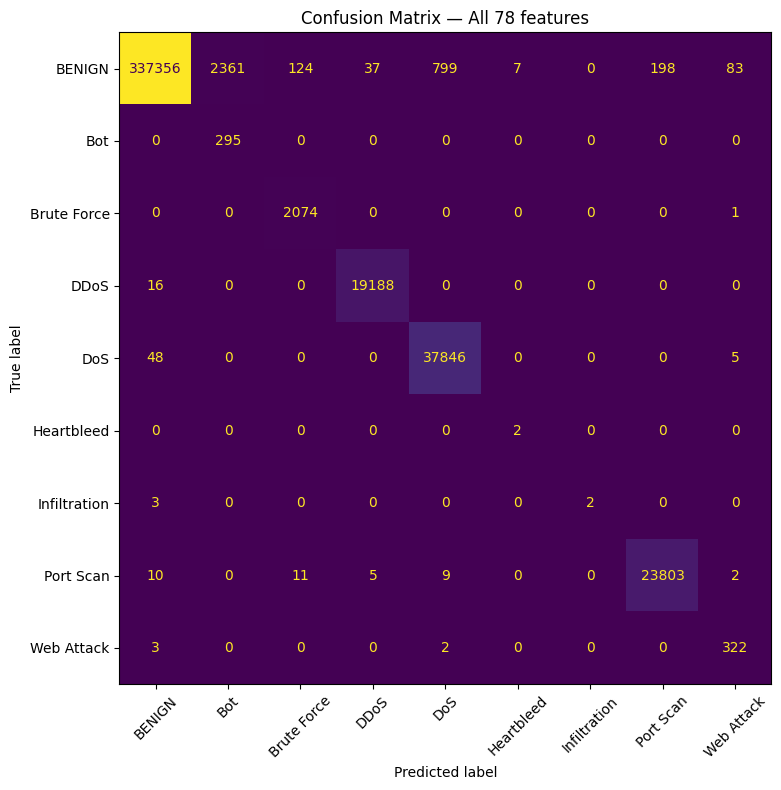


Top 30 features
Class order: ['BENIGN', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'Heartbleed', 'Infiltration', 'Port Scan', 'Web Attack']
[[337834   1256     64     32    478      3      0    344    954]
 [     0    295      0      0      0      0      0      0      0]
 [     0      0   2074      0      0      0      0      0      1]
 [    15      0      0  19189      0      0      0      0      0]
 [    33      0      0      0  37862      0      0      0      4]
 [     0      0      0      0      0      2      0      0      0]
 [     3      0      0      0      0      0      2      0      0]
 [    10      0     11      0      9      0      0  23808      2]
 [     3      0      0      0      0      0      0      0    324]]


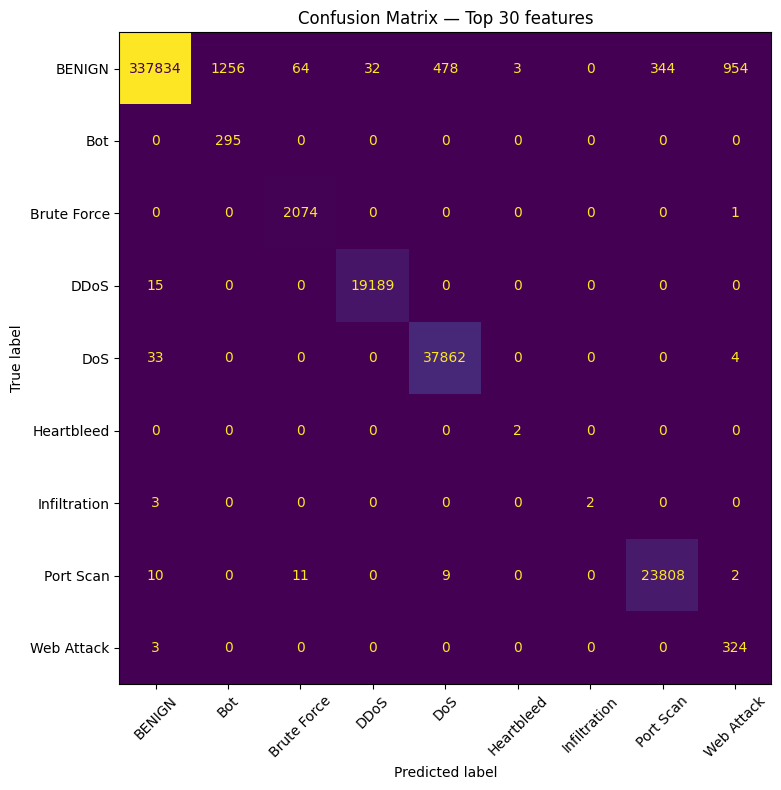

In [58]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in trained_models.items():
    selected_features = feature_sets[name]
    y_pred = model.predict(X_val[selected_features])

    labels = model.classes_

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=labels
    )

    print(f"\n{name}")
    print("Class order:", list(labels))
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    fig, ax = plt.subplots(figsize=(11, 8))
    disp.plot(
        ax=ax,
        xticks_rotation=45,
        values_format="d",
        colorbar=False
    )
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


In [59]:

# Select 500 records to estimate SHAP importance
X_shap = X_rf.sample(
    n=min(500, len(X_rf)),
    random_state=42
)

# Explain predictions from your trained Random Forest
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_shap)

# Handle SHAP output from different SHAP versions
if isinstance(shap_values, list):
    # Older SHAP versions: one array per class
    shap_array = np.stack(shap_values, axis=-1)
else:
    shap_array = np.asarray(shap_values)

print("SHAP output shape:", shap_array.shape)
print("Input shape:", X_shap.shape)


SHAP output shape: (500, 78, 9)
Input shape: (500, 78)


In [60]:

# Average absolute SHAP value for each feature
shap_importance_values = np.mean(
    np.abs(shap_array),
    axis=(0, 2)
)

# Create the SHAP importance ranking
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "SHAP Importance": shap_importance_values
}).sort_values(
    by="SHAP Importance",
    ascending=False
).reset_index(drop=True)

# Extract the top 30 features
top_30_shap_features = shap_importance.head(30)["Feature"].tolist()

print("Top 30 SHAP features:")
print(shap_importance.head(30).to_string(index=False))


Top 30 SHAP features:
                    Feature  SHAP Importance
           Destination Port         0.031246
       min_seg_size_forward         0.012478
      Bwd Packet Length Min         0.010511
    Init_Win_bytes_backward         0.010395
         Packet Length Mean         0.008447
          Subflow Fwd Bytes         0.007967
      Fwd Packet Length Max         0.006941
          Subflow Bwd Bytes         0.006918
Total Length of Fwd Packets         0.006778
        Average Packet Size         0.006379
       Avg Fwd Segment Size         0.006323
     Fwd Packet Length Mean         0.006106
     Bwd Packet Length Mean         0.005631
       Avg Bwd Segment Size         0.005557
      Bwd Packet Length Std         0.005471
Total Length of Bwd Packets         0.005422
     Init_Win_bytes_forward         0.005196
          Fwd Header Length         0.004987
          Packet Length Std         0.004984
               Flow Bytes/s         0.004778
      Bwd Packet Length Max      

In [61]:

# Features selected by both methods
common_features = sorted(
    set(top_30_features) & set(top_30_shap_features)
)

# Features selected only by Random Forest
rf_only_features = sorted(
    set(top_30_features) - set(top_30_shap_features)
)

# Features selected only by SHAP
shap_only_features = sorted(
    set(top_30_shap_features) - set(top_30_features)
)

print("Random Forest top 30:", len(top_30_features))
print("SHAP top 30:", len(top_30_shap_features))
print("Common features:", len(common_features))

print("\nFeatures selected by both methods:")
print(common_features)

print("\nOnly in Random Forest top 30:")
print(rf_only_features)

print("\nOnly in SHAP top 30:")
print(shap_only_features)

Random Forest top 30: 30
SHAP top 30: 30
Common features: 28

Features selected by both methods:
['Average Packet Size', 'Avg Bwd Segment Size', 'Avg Fwd Segment Size', 'Bwd Header Length', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Min', 'Bwd Packets/s', 'Destination Port', 'Flow Bytes/s', 'Fwd Header Length', 'Fwd Header Length.1', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Init_Win_bytes_backward', 'Init_Win_bytes_forward', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'Subflow Bwd Bytes', 'Subflow Fwd Bytes', 'Subflow Fwd Packets', 'Total Backward Packets', 'Total Fwd Packets', 'Total Length of Bwd Packets', 'Total Length of Fwd Packets', 'min_seg_size_forward']

Only in Random Forest top 30:
['Fwd IAT Max', 'act_data_pkt_fwd']

Only in SHAP top 30:
['Bwd Packet Length Std', 'Fwd Packet Length Std']


In [62]:
import time

feature_sets = {
    "All 78 features": all_features,
    "Random Forest top 30": top_30_features,
    "SHAP top 30": top_30_shap_features
}

results = []
trained_models = {}

for name, selected_features in feature_sets.items():
    print(f"\nTraining: {name}")

    model = RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        random_state=0,
        n_jobs=-1
    )

    start = time.time()

    model.fit(X_rf[selected_features], y_rf)

    training_time = time.time() - start

    y_pred = model.predict(X_val[selected_features])

    results.append({
        "Feature Set": name,
        "Number of Features": len(selected_features),
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": f1_score(
            y_val, y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Training Time (seconds)": round(training_time, 2)
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(results)

print("\nFinal comparison:")
print(comparison_df.to_string(index=False))



Training: All 78 features

Training: Random Forest top 30

Training: SHAP top 30

Final comparison:
         Feature Set  Number of Features  Accuracy  Macro F1  Weighted F1  Training Time (seconds)
     All 78 features                  78  0.991230  0.772265     0.993464                     1.01
Random Forest top 30                  30  0.992412  0.758425     0.994084                     0.87
         SHAP top 30                  30  0.992329  0.770815     0.993925                     0.81


In [63]:
for name, model in trained_models.items():
    selected_features = feature_sets[name]

    y_pred = model.predict(X_val[selected_features])

    report = classification_report(
        y_val,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    # Keep individual attack classes only
    report_df = report_df.loc[
        ~report_df.index.isin(
            ["accuracy", "macro avg", "weighted avg"]
        )
    ]

    print(f"\n{name}")
    print(
        report_df[
            ["precision", "recall", "f1-score", "support"]
        ].round(4).to_string()
    )



All 78 features
              precision  recall  f1-score   support
BENIGN           0.9998  0.9894    0.9946  340965.0
Bot              0.1111  1.0000    0.1999     295.0
Brute Force      0.9389  0.9995    0.9683    2075.0
DDoS             0.9978  0.9992    0.9985   19204.0
DoS              0.9790  0.9986    0.9887   37899.0
Heartbleed       0.2222  1.0000    0.3636       2.0
Infiltration     1.0000  0.4000    0.5714       5.0
Port Scan        0.9918  0.9984    0.9951   23840.0
Web Attack       0.7797  0.9847    0.8703     327.0

Random Forest top 30
              precision  recall  f1-score   support
BENIGN           0.9998  0.9908    0.9953  340965.0
Bot              0.1902  1.0000    0.3196     295.0
Brute Force      0.9651  0.9995    0.9820    2075.0
DDoS             0.9983  0.9992    0.9988   19204.0
DoS              0.9873  0.9990    0.9931   37899.0
Heartbleed       0.4000  1.0000    0.5714       2.0
Infiltration     1.0000  0.4000    0.5714       5.0
Port Scan        0.9858  